# 02 — Win model baselines: constant prior → logistic regression

**Why start here.** Logistic regression (LR) is the "hello world" that every fancier model must beat. It's fast
and hard to overfit with regularisation, and every coefficient is readable: *one standard deviation more of X
changes the log-odds of a blue win by β*.

**How we judge it.**
* **Time-based split**: train on older games, validate on newer ones, keep a final test block sealed. Player form
  drifts and players reappear, so a random split would let the model peek at the future.
* **Log loss / Brier score**, not accuracy: we want *honest* probabilities ("63 %" should win ~63 % of the time).
  Accuracy only checks which side of 50 % we landed on.
* **Expectation**: pre-game prediction is hard. Beating the constant baseline's log loss (~0.693) by 0.005–0.02
  is a real result. AUC above ~0.65 means hunt for a leak before celebrating.

In [1]:
# Setup: works locally (Jupyter started in the repo or in training/) and on Google Colab.
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/oracle-training")   # <- the folder you uploaded (see training/README.md)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap"], check=True)
else:
    ROOT = Path.cwd() if (Path.cwd() / "trainlib.py").exists() else Path.cwd() / "training"
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import trainlib as tl

# Known harmless library notices (kept out of the saved outputs):
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")              # LightGBM 4.7 rename; old name works everywhere
warnings.filterwarnings("ignore", message="IProgress not found")                  # shap's progress bar widget
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

SEED = 42   # passed as random_state to every model, so runs are reproducible
pd.set_option("display.width", 160, "display.max_columns", 40)

b = tl.load(os.environ.get("ORACLE_BUNDLE", ROOT / "data"))   # newest bundle in data/
print(b.describe())
if len(b.matches) < 500:
    print(f"\n!! Only {len(b.matches)} games: numbers below are mostly noise. Treat this run as a pipeline check "
          "and re-run after more crawling.")

win_v1@548a7d0e28  built 2026-11-05T11:29:28+00:00
rows: 42 matches, 420 seats (skipped: {'incomplete_history': 40})
time: ['2026-06-24T14:55+00:00', '2026-10-20T17:45+00:00']
patches: 16.13, 16.15, 16.17, 16.18, 16.19, 16.20
features: 102 match-level, 32 per seat

!! Only 42 games: numbers below are mostly noise. Treat this run as a pipeline check and re-run after more crawling.


## 1. Split by time

In [2]:
# Columns that have at least some values in TRAIN (rank/mastery are all-empty until clean snapshots exist).
def usable(cols, df):
    return [c for c in cols if df[c].notna().any() and df[c].nunique(dropna=True) > 1]

split = tl.time_split(b.matches, val=0.15, test=0.15, embargo_h=1)
print(split)
ALL = usable(b.features, split.train)
print(f"{len(ALL)} usable features of {len(b.features)}")

train    29 rows  2026-06-24 .. 2026-10-05  blue win 0.517
val       6 rows  2026-10-09 .. 2026-10-11  blue win 0.500
test      7 rows  2026-10-12 .. 2026-10-20  blue win 0.857
82 usable features of 102


## 2. Baseline 0: always predict the training blue-win rate
Any model that can't beat this has learned nothing.

In [3]:
results = []
p_const = np.full(len(split.val), split.train["y_blue_win"].mean())
results.append(tl.evaluate(split.val["y_blue_win"], p_const, "constant prior"))
tl.compare(results)

,n,log_loss,brier,auc,accuracy,vs_first_logloss
model,,,,,,
constant prior,6,0.6937,0.2503,0.5,0.5,0.0


## 3. Baseline 1: a few hand-picked features
The pipeline (imputer → scaler → LR) is fitted on TRAIN only, so imputation medians and scaling come from the
past too.
* `SimpleImputer(add_indicator=True)` fills NaN with the median and adds a "was missing" 0/1 column, so the
  model can learn that "unknown" differs from "average".
* `StandardScaler` puts features on one scale, so regularisation treats them fairly and coefficients compare.
* `C` is the inverse regularisation strength: smaller C means a simpler model.

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def lr(C=1.0):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=C, max_iter=2000))

FEW = [c for c in ["d_mean_wr_shrunk", "d_mean_kda", "d_mean_champ_games", "d_mean_champ_meta_wr",
                   "d_mean_off_role", "d_min_n_games", "d_mean_streak"] if c in ALL]
lr_few = lr(C=0.1).fit(split.train[FEW], split.train["y_blue_win"])
results.append(tl.evaluate(split.val["y_blue_win"], lr_few.predict_proba(split.val[FEW])[:, 1], "LR few"))
tl.compare(results)

,n,log_loss,brier,auc,accuracy,vs_first_logloss
model,,,,,,
constant prior,6,0.6937,0.2503,0.5000,0.5000,0.0000
LR few,6,0.6493,0.2281,0.6667,0.6667,-0.0445


## 4. LR on all features, regularisation tuned by forward-chaining CV
`GridSearchCV` with `tl.rolling_origin` folds always trains on the past and validates on the next block, inside
TRAIN only. Validation stays untouched for an honest comparison.

In [5]:
from sklearn.model_selection import GridSearchCV

train = split.train
if len(train) >= 200:
    search = GridSearchCV(lr(), {"logisticregression__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]},
                          cv=tl.rolling_origin(train, n_folds=4), scoring="neg_log_loss", error_score=np.nan)
    search.fit(train[ALL], train["y_blue_win"])
    BEST_C = search.best_params_["logisticregression__C"]
    print(f"best C: {BEST_C}   cv log loss: {-search.best_score_:.4f}")
else:   # CV folds of a few games often contain only wins or only losses: tuning would be meaningless
    BEST_C = 0.03
    print(f"only {len(train)} training games: skipping CV, using C = {BEST_C}")
lr_all = lr(C=BEST_C).fit(train[ALL], train["y_blue_win"])
p_lr = lr_all.predict_proba(split.val[ALL])[:, 1]
results.append(tl.evaluate(split.val["y_blue_win"], p_lr, "LR all (tuned C)"))
tl.compare(results)

only 29 training games: skipping CV, using C = 0.03


,n,log_loss,brier,auc,accuracy,vs_first_logloss
model,,,,,,
constant prior,6,0.6937,0.2503,0.5000,0.5000,0.0000
LR few,6,0.6493,0.2281,0.6667,0.6667,-0.0445
LR all (tuned C),6,0.6623,0.2345,0.6667,0.6667,-0.0315


### How sure are we? A bootstrap interval by week
Rows share players and days, so we resample whole **weeks**, not single games. If the interval of the
improvement contains 0, we can't claim the model beats the baseline yet.

In [6]:
yv = split.val["y_blue_win"].to_numpy()
weeks = len(np.unique(tl.week_of(split.val)))
lo, hi = tl.bootstrap_ci(yv, p_lr, groups=tl.week_of(split.val))
if weeks < 5:
    print(f"(validation spans only {weeks} week(s): this interval is not meaningful yet)")
print(f"LR all val log loss 95% CI: {lo:.4f} .. {hi:.4f}   (constant ≈ {results[0]['log_loss']:.4f})")

(validation spans only 1 week(s): this interval is not meaningful yet)


LR all val log loss 95% CI: 0.6623 .. 0.6623   (constant ≈ 0.6937)


## 5. Calibration
Points on the diagonal mean honest probabilities. LR is usually well calibrated out of the box. Noisy here when
validation is small.

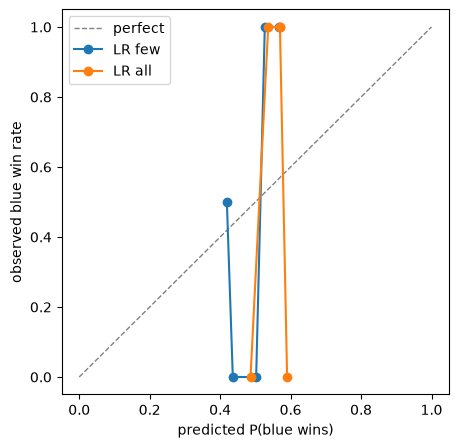

In [7]:
tl.reliability_plot(split.val["y_blue_win"], {"LR few": lr_few.predict_proba(split.val[FEW])[:, 1],
                                               "LR all": p_lr}, bins=5)
plt.show()

## 6. What did it learn?
Standardised coefficients: the change in log-odds of a blue win per +1 SD of the feature (blue − red).
The **intercept** is the blue-side advantage after accounting for the features: every column is antisymmetric
(blue − red), so nothing else can absorb it.

In [8]:
imp, scaler, model = lr_all.named_steps.values()
names = list(imp.get_feature_names_out(ALL))
coefs = pd.Series(model.coef_[0], index=names).sort_values(key=abs, ascending=False)
print(f"intercept {model.intercept_[0]:+.3f}  ->  P(blue) at equal teams = {1 / (1 + np.exp(-model.intercept_[0])):.3f}")
coefs.head(20).round(3)

intercept +0.067  ->  P(blue) at equal teams = 0.517


ctx_n_games                 0.127
lane_MIDDLE_champ_games     0.124
d_mean_session_losses       0.114
lane_TOP_off_role           0.110
lane_BOTTOM_off_role       -0.099
d_mean_session_games        0.096
lane_UTILITY_champ_games   -0.089
lane_TOP_gold_pm            0.088
lane_MIDDLE_cs_pm          -0.077
d_mean_wr_recent           -0.076
d_mean_champ_meta_games     0.075
lane_UTILITY_off_role      -0.065
d_max_wr_shrunk            -0.059
lane_TOP_kda                0.050
d_min_champ_meta_wr        -0.050
lane_MIDDLE_gold_pm        -0.049
lane_JUNGLE_wr_shrunk      -0.046
d_mean_streak              -0.046
d_mean_hours_since_last    -0.045
lane_BOTTOM_champ_games     0.043
dtype: float64

## 7. Explaining one game (joke ingredients)
For LR, the log-odds split exactly into one contribution per feature: coefficient × scaled value. The biggest
ones are what the oracle should talk about ("your mid has a −5 streak"). The per-player values behind each
`d_mean_*` come from `seats.parquet`.

In [9]:
game = split.val.index[-1]
x = scaler.transform(imp.transform(split.val.loc[[game], ALL]))[0]
contrib = pd.Series(model.coef_[0] * x, index=names).sort_values(key=abs, ascending=False)
p = lr_all.predict_proba(split.val.loc[[game], ALL])[0, 1]
print(f"{game}: P(blue wins) = {p:.1%}, actual blue win = {split.val.loc[game, 'y_blue_win']}")
display(contrib.head(8).round(3).to_frame("logit contribution"))
display(b.seats[b.seats["game"] == game][["side", "role", "champion_id", "n_games", "streak", "kda",
                                           "champ_games", "off_role", "is_tracked"]])

EUN1_4013827046: P(blue wins) = 57.0%, actual blue win = 1


,logit contribution
ctx_n_games,0.160
lane_MIDDLE_champ_games,-0.156
lane_UTILITY_champ_games,0.131
lane_UTILITY_off_role,-0.128
lane_JUNGLE_wr_shrunk,0.102
d_max_wr_shrunk,0.084
d_mean_days_since_champ,0.084
d_mean_champ_meta_games,0.057


,side,role,champion_id,n_games,streak,kda,champ_games,off_role,is_tracked
340,100,TOP,82,20.0,2.0,0.838732,0.0,0.0,0
341,100,JUNGLE,62,20.0,-2.0,1.009744,0.0,1.0,1
342,100,MIDDLE,157,20.0,1.0,0.818535,0.0,0.0,0
343,100,BOTTOM,45,19.0,1.0,0.602175,4.0,0.0,0
344,100,UTILITY,910,20.0,-2.0,0.964674,1.0,1.0,1
345,200,TOP,875,20.0,-1.0,0.275763,18.0,0.0,0
346,200,JUNGLE,59,19.0,1.0,0.940244,0.0,1.0,0
347,200,MIDDLE,112,19.0,-2.0,0.826265,9.0,0.0,0
348,200,BOTTOM,523,20.0,-1.0,0.589157,1.0,0.0,0
349,200,UTILITY,40,19.0,-1.0,1.036346,11.0,0.0,0


## 8. Final test (sealed)
Only run this once you've finished choosing models on validation. Looking at test repeatedly turns it into a
second validation set, and the number stops being honest.

In [10]:
EVALUATE_TEST = False
if EVALUATE_TEST and len(split.test):
    final = lr(C=BEST_C).fit(
        pd.concat([split.train, split.val])[ALL], pd.concat([split.train, split.val])["y_blue_win"])
    print(tl.compare([tl.evaluate(split.test["y_blue_win"], np.full(len(split.test), split.train["y_blue_win"].mean()), "constant"),
                      tl.evaluate(split.test["y_blue_win"], final.predict_proba(split.test[ALL])[:, 1], "LR all")]))

## 9. Save the model + model card

In [11]:
path = tl.save_model(ROOT / "artifacts" / "win_lr", lr_all, b, ALL, results,
                     notes="LR baseline, median imputation + indicators, C tuned by rolling-origin CV")
print("saved to", path)

saved to /Users/tomaspham/Projects/Boosted-Baron/training/artifacts/win_lr
